# Fine-tuning

> Fine-tuning the pretrained CNNs on the soils of one instrument, against PLSR trained on the same soils

In [ ]:
#| default_exp finetune

In [ ]:
#| export
import copy
from pathlib import Path
import numpy as np, pandas as pd
from fastai.torch_core import set_seed
from fastai.metrics import AccumMetric, R2Score
from scipy.stats import wilcoxon
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer
from soilspectfm.preprocessing import SNV, SavitzkyGolay
from soilspecdl.all import BatchSNV, CutCNN, get_spectral_dls, group_folds, predict, regression_scores, ridge_head, spectral_learner
from ossl_rt_transfer.pretrain import rt_wns, preprocess, log_props, model_dir
from ossl_rt_transfer.instrument_model import co2_region

/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [ ]:
import matplotlib.pyplot as plt
from fastcore.test import *
from soilspecdl.all import SpectralCNN, regression_scores
from soilspecdata.datasets.ringtrial import load_ringtrial
from ossl_rt_transfer.data import rt_path, near_dup_groups
from ossl_rt_transfer.pretrain import model_dir, load_pretrained

The cells that read the ring-trial data and train are marked `#| rtdata`. The outputs on this page come from a local run.

This notebook tests what the pretrained CNNs gain from the soils of one instrument. On each instrument, the soils are split into grouped folds, and each method is trained on the other folds and predicts the held-out fold:

- `zero-shot`: the pretrained model as it is, for reference.
- `ridge block 4`: ridge regression on the frozen features of block 4, every channel at every position. In `ossl-fuku-transfer` this was best or level with the best at every training size.
- `fine-tuned`: all of the pretrained model, fine-tuned with a one-cycle schedule.
- `PLSR`: PLSR trained only on the instrument's soils, with the preprocessing of mirzai and its number of components chosen by inner grouped cross-validation.

The CNN methods start from three pretrained models: the augmented 160-epoch models of `06_aug_pretrain`, the augmented 20-epoch models of `05_augment`, and the unaugmented 80-epoch models of `01_pretrain`. This first run covers K, the main property, and clay, the control, on two instruments: KSSL, where pretraining has no instrument gap, and IAEA, the instrument of the Fukushima scans and the farthest from KSSL.

## Data and folds

`rt_xy` gives the spectra of one instrument after SNV, with the targets on the scale the models use: `log1p` for K. Every method gets these spectra. A second SNV, as in `BatchSNV` and in the PLSR pipeline, leaves them unchanged:

In [ ]:
#| export
def rt_xy(
    spectra, # `Spectra` of one ring-trial instrument
    prop, # Ring-trial property, a key of `ossl_props`
)->tuple: # SNV spectra, targets (`log1p` for the properties in `log_props`), sample ids
    "Spectra and targets of the soils of one instrument that have a value of `prop`, on the scale the models use"
    X, y, ids = spectra.xy(prop)
    y = y.ravel()
    return preprocess().fit_transform(X), (np.log1p(y) if prop in log_props else y), np.asarray(ids)


`soil_folds` deals the near-duplicate groups of `00_data` into folds. The folds are set by sample id, so a soil is in the same fold on every instrument, and the predictions of two instruments can be compared soil by soil:

In [ ]:
#| export
def soil_folds(
    groups:pd.Series, # Near-duplicate group of each soil, indexed by sample id
    k=10, # Number of folds
    repeats=10, # Number of fold assignments
)->pd.DataFrame: # Fold of each soil, one row per repeat, one column per sample id
    "Grouped k-fold assignments, the same for a soil on every instrument"
    return pd.DataFrame([group_folds(groups.values, k, seed=r) for r in range(repeats)], columns=groups.index)

In [ ]:
g = pd.Series([0, 0, 1, 2, 3, 4, 5, 5], index=[f'RT_{i}' for i in range(8)])
f = soil_folds(g, k=3, repeats=4)
test_eq(f.shape, (4, 8))
test_eq((f['RT_0'] == f['RT_1']).all(), True)
test_eq(f.loc[2, ['RT_6', 'RT_7']].nunique(), 1)

## Methods

`plsr` follows the PLSR pipeline of mirzai: SNV, a Savitzky-Golay first derivative with a window of 11 points and a polynomial of degree 1, and removal of the CO₂ region. `fit_plsr` chooses the number of components by grouped cross-validation on the training soils. `finetune` fine-tunes all of a copy of the pretrained model. The held-out soils are its validation set, so the loss, R² and bias on them are recorded after every epoch, but they play no part in training. `ridge_block4` fits ridge regression on the frozen block-4 features, with the penalty chosen by leave-one-out cross-validation:

In [ ]:
#| export
def _drop_co2(X): return X[:, (rt_wns < co2_region[0]) | (rt_wns > co2_region[1])]

def plsr(
    n_components=10, # Number of PLS components
):
    "PLSR with the preprocessing of mirzai: SNV, Savitzky-Golay first derivative, CO₂ region removed"
    return make_pipeline(SNV(), SavitzkyGolay(11, 1, 1), FunctionTransformer(_drop_co2), PLSRegression(n_components))

def fit_plsr(
    X, # Spectra on `rt_wns`, one per row
    y, # Targets
    groups, # Near-duplicate group of each soil
    max_components=15, # Largest number of components to try
    k=5, # Number of inner folds
):
    "`plsr` with the number of components that grouped inner cross-validation chooses"
    gs = GridSearchCV(plsr(), {'plsregression__n_components': range(1, max_components + 1)},
                      cv=GroupKFold(k), scoring='neg_mean_squared_error')
    return gs.fit(X, y, groups=groups).best_estimator_

def _bias(p, t): return (p - t).mean()

def finetune(
    model, # Pretrained model
    X, # SNV spectra on `rt_wns`, one per row
    y, # Targets
    train, # Indices of the training soils
    test, # Indices of the held-out soils, only scored
    epochs, # Number of one-cycle epochs
    lr=3e-3, # Maximum learning rate
    bs=16, # Batch size, capped at the number of training soils
    seed=0, # Seed for the training
)->tuple: # Predictions for `test`, and the held-out loss, R² and bias after each epoch
    "Fine-tune a copy of all of `model` on the soils `train`"
    set_seed(seed)
    dls, _ = get_spectral_dls(X, y, rt_wns, splitter=lambda X, y: (train, test, test), bs=min(bs, len(train)), batch_tfms=[BatchSNV()])
    learn = spectral_learner(dls, copy.deepcopy(model), metrics=[R2Score(), AccumMetric(_bias, flatten=True)])
    with learn.no_bar(), learn.no_logging(): learn.fit_one_cycle(epochs, lr_max=lr)
    hist = pd.DataFrame(learn.recorder.values, columns=['train_loss', 'valid_loss', 'r2', 'bias']).rename_axis('epoch').reset_index()
    with learn.no_bar(): p, _ = learn.get_preds(dl=dls.valid)
    return p.numpy().ravel(), hist

def ridge_block4(
    model, # Pretrained `SpectralCNN`
    X, # SNV spectra on `rt_wns`, one per row
    y, # Targets
    train, # Indices of the training soils
    test, # Indices of the soils to predict
)->np.ndarray: # Predictions for `test`
    "Ridge regression on the frozen block-4 features of `model`, every channel at every position"
    m = ridge_head(CutCNN(model, len(rt_wns), flat=True), X[train], y[train], rt_wns)
    return predict(m, X[test], rt_wns).ravel()

On random spectra and targets, each method returns one prediction per held-out soil, and `finetune` one row of history per epoch:

In [ ]:
rng = np.random.default_rng(0)
Xs = preprocess().fit_transform(rng.uniform(0.2, 2, (40, len(rt_wns))))
ys, gs = rng.normal(size=40), np.arange(40) // 2
tr, te = np.arange(30), np.arange(30, 40)
test_eq(fit_plsr(Xs[tr], ys[tr], gs[tr], max_components=3).predict(Xs[te]).shape, (10,))
p, h = finetune(SpectralCNN(), Xs, ys, tr, te, epochs=2)
test_eq(p.shape, (10,))
test_eq(h.columns.tolist(), ['epoch', 'train_loss', 'valid_loss', 'r2', 'bias'])
test_eq(len(h), 2)
test_eq(ridge_block4(SpectralCNN(), Xs, ys, tr, te).shape, (10,))

`choose_epochs` cross-validates `finetune` over several numbers of epochs. `cv_cnn` and `cv_plsr` give the held-out predictions of every fold of every repeat, one row per soil:

In [ ]:
#| export
def choose_epochs(
    model, # Pretrained model
    X, # SNV spectra on `rt_wns`, one per row
    y, # Targets
    groups, # Near-duplicate group of each soil
    grid=(10, 30, 100, 200), # Numbers of epochs to try
    k=5, # Number of folds
)->pd.Series: # Mean held-out loss at the last epoch, for each number of epochs
    "Grouped cross-validation of `finetune` over the numbers of epochs in `grid`"
    splits = list(GroupKFold(k).split(X, y, groups))
    return pd.Series({e: np.mean([finetune(model, X, y, tr, te, e)[1].valid_loss.iloc[-1] for tr, te in splits]) for e in grid},
                     name='valid_loss').rename_axis('epochs')

def cv_cnn(
    model, # Pretrained model
    X, # SNV spectra on `rt_wns`, one per row
    y, # Targets
    ids, # Sample id of each row
    folds, # Fold of each soil, from `soil_folds`
    epochs, # Number of fine-tuning epochs
)->tuple: # Held-out predictions, and the fine-tuning histories
    "Held-out predictions of the pretrained model as it is, the block-4 ridge and the fine-tuned model, for every fold of every repeat"
    p0, preds, hists = predict(model, X, rt_wns).ravel(), [], []
    for r, f in folds[ids].iterrows():
        f = f.values
        for k in np.unique(f):
            tr, te = np.flatnonzero(f != k), np.flatnonzero(f == k)
            pf, h = finetune(model, X, y, tr, te, epochs, seed=r)
            hists.append(h.assign(repeat=r, fold=k))
            for m, p in [('zero-shot', p0[te]), ('ridge block 4', ridge_block4(model, X, y, tr, te)), ('fine-tuned', pf)]:
                preds.append(pd.DataFrame({'method': m, 'repeat': r, 'fold': k, 'sample_id': ids[te], 'y': y[te], 'pred': p}))
    return pd.concat(preds, ignore_index=True), pd.concat(hists, ignore_index=True)

def cv_plsr(
    X, # Spectra on `rt_wns`, one per row
    y, # Targets
    ids, # Sample id of each row
    groups:pd.Series, # Near-duplicate group of each soil, indexed by sample id
    folds, # Fold of each soil, from `soil_folds`
)->pd.DataFrame: # Held-out predictions
    "Held-out predictions of `fit_plsr`, for every fold of every repeat"
    g, preds = groups[ids].values, []
    for r, f in folds[ids].iterrows():
        f = f.values
        for k in np.unique(f):
            tr, te = np.flatnonzero(f != k), np.flatnonzero(f == k)
            p = fit_plsr(X[tr], y[tr], g[tr]).predict(X[te]).ravel()
            preds.append(pd.DataFrame({'method': 'PLSR', 'repeat': r, 'fold': k, 'sample_id': ids[te], 'y': y[te], 'pred': p}))
    return pd.concat(preds, ignore_index=True)

In [ ]:
ids = np.array([f'RT_{i}' for i in range(40)])
fs = soil_folds(pd.Series(gs, index=ids), k=4, repeats=2)
pc, hc = cv_cnn(SpectralCNN(), Xs, ys, ids, fs, epochs=1)
test_eq(len(pc), 3 * 2 * 40)
test_eq(pc.groupby(['method', 'repeat']).sample_id.nunique().unique(), [40])
test_eq(len(cv_plsr(Xs, ys, ids, pd.Series(gs, index=ids), fs)), 2 * 40)

`paired_test` compares two methods on the same units, such as soils or groups of near-duplicate soils. It takes the error of each method on each unit and applies a Wilcoxon signed-rank test to the differences:

In [ ]:
#| export
def paired_test(
    a:pd.Series, # Error of method A on each unit, such as the mean squared error of a group of soils
    b:pd.Series, # Error of method B on the same units
)->dict: # Number of units, mean error of A and B, share of units where A has the smaller error, Wilcoxon p-value
    "Wilcoxon signed-rank test of paired errors of two methods"
    a, b = a.align(b, join='inner')
    return dict(n=len(a), A=float(a.mean()), B=float(b.mean()), A_better=float((a < b).mean()), p=float(wilcoxon(a, b).pvalue))

In [ ]:
e = pd.Series(rng.uniform(size=30))
r = paired_test(e, e + 0.1)
test_eq((r['n'], r['A_better']), (30, 1.))
assert r['p'] < 1e-3
test_eq(paired_test(e, e[::-1].reset_index(drop=True))['n'], 30)

`cached` saves each result table as a CSV file, so a rerun of a notebook loads it instead of computing it again:

In [ ]:
#| export
def cached(
    fname, # File name, without the `.csv` suffix
    f, # Function that computes the DataFrame
    path=None, # Folder of the file, by default `finetune` in `model_dir()`
)->pd.DataFrame: # The saved DataFrame, or the result of `f`
    "Load the DataFrame saved under `fname`, or compute it with `f` and save it"
    fn = Path(path or model_dir()/'finetune')/f'{fname}.csv'
    if fn.exists(): return pd.read_csv(fn, index_col=0)
    fn.parent.mkdir(parents=True, exist_ok=True)
    df = f(); df.to_csv(fn); return df

In [ ]:
import tempfile
with tempfile.TemporaryDirectory() as d:
    df = cached('t', lambda: pd.DataFrame({'a': [1, 2]}), d)
    test_eq(cached('t', lambda: None, d), df)

`repeat_scores` scores each repeat for each group of rows, pooling the held-out predictions of its folds. R² and CCC are on the scale the models use; RMSE and bias are on the property's own scale. `group_errors` averages the squared error on the model scale over the repeats and over the soils of each near-duplicate group, the unit of `paired_test`:

In [ ]:
#| export
def repeat_scores(
    preds:pd.DataFrame, # Held-out predictions, with columns `property`, `repeat`, `y` and `pred`
    keys=('instrument', 'property', 'start', 'method'), # Columns that define a group of rows
)->pd.DataFrame: # Scores of `regression_scores`, one row per group and repeat
    "Scores of each repeat for each group of `keys`, each repeat pooling the held-out predictions of its folds"
    keys = list(keys)
    def f(d):
        inv = np.expm1 if d.name[keys.index('property')] in log_props else None
        return pd.DataFrame({r: regression_scores(e.y, e.pred, inv=inv) for r, e in d.groupby('repeat')}).T.rename_axis('repeat')
    return preds.groupby(keys).apply(f, include_groups=False)

def group_errors(
    preds:pd.DataFrame, # Held-out predictions, with columns `sample_id`, `y` and `pred`
    groups:pd.Series, # Near-duplicate group of each soil, indexed by sample id
    keys=('instrument', 'property', 'start', 'method'), # Columns that define a group of rows
)->pd.Series: # Mean squared error, indexed by `keys` and `group`
    "Mean squared error on the model scale of each near-duplicate group, over its soils and the repeats"
    return (preds.assign(group=preds.sample_id.map(groups), se=(preds.pred - preds.y)**2)
            .groupby(list(keys) + ['group']).se.mean())

In [ ]:
tp = pd.DataFrame({'instrument': 'A', 'property': 'potassium_cmolkg', 'start': 's', 'method': 'm', 'repeat': np.repeat([0, 1], 4),
                   'sample_id': ['a', 'b', 'c', 'd'] * 2, 'y': [0., 1, 2, 3] * 2, 'pred': [0., 1, 2, 3] * 2})
test_eq(repeat_scores(tp)['R²'].tolist(), [1., 1.])
test_eq(group_errors(tp, pd.Series([0, 0, 1, 1], index=list('abcd'))).tolist(), [0., 0.])

## Number of epochs

On 63 training soils with a batch size of 16, an epoch is 3 or 4 optimiser steps. The `ossl-fuku-transfer` schedule of 20 epochs was chosen on about 1,000 samples and does not carry over. The number of epochs is chosen once for each property and starting model, by grouped 5-fold cross-validation over the KSSL soils, from 10, 30, 100 and 200 epochs. The same number then applies to every fold, repeat and instrument. Every KSSL soil is a test soil in some fold of the main run, so this choice uses soils that the main run later tests. It is one number out of four, so the optimism this adds is small. The table gives the mean held-out loss at the last epoch:

In [ ]:
#| rtdata
rt = load_ringtrial(rt_path())
groups = pd.Series(near_dup_groups(rt['KSSL']), index=rt['KSSL'].sample_ids)
props, insts = ['potassium_cmolkg', 'clay_perc'], ['KSSL', 'IAEA_aug2022']
starts = {'augmented 160': 'aug_ep160', 'augmented 20': 'aug_ep20', 'not augmented 80': 'snv_ep80'}
models = {(p, s): load_pretrained(f'ossl_{p}_{f}') for p in props for s, f in starts.items()}
res_dir = model_dir()/'finetune'; res_dir.mkdir(exist_ok=True)
def epoch_table(p):
    X, y, ids = rt_xy(rt['KSSL'], p)
    return pd.DataFrame({s: choose_epochs(models[(p, s)], X, y, groups[ids].values) for s in starts})
ep_cv = pd.concat({p: cached(f'epochs_{p}', lambda: epoch_table(p)) for p in props})
ep_cv.round(4)

augmented 160  augmented 20  not augmented 80
                 epochs                                               
potassium_cmolkg 10             0.0302        0.0343            0.0317
                 30             0.0227        0.0242            0.0212
                 100            0.0229        0.0228            0.0211
                 200            0.0233        0.0215            0.0210
clay_perc        10            25.0278       30.1643           27.5450
                 30            17.9355       26.6469           19.2665
                 100           26.7567       26.0922           27.8721
                 200           27.7100       30.5101           30.1152

In [ ]:
#| rtdata
n_epochs = {(p, s): int(ep_cv.loc[p, s].idxmin()) for p in props for s in starts}
n_epochs

{('potassium_cmolkg', 'augmented 160'): 30,
 ('potassium_cmolkg', 'augmented 20'): 200,
 ('potassium_cmolkg', 'not augmented 80'): 200,
 ('clay_perc', 'augmented 160'): 30,
 ('clay_perc', 'augmented 20'): 100,
 ('clay_perc', 'not augmented 80'): 30}

For K, the held-out loss changes little from 30 to 200 epochs, so the choice between them matters little. For clay, the loss is not monotonic in the number of epochs: 30 epochs is best for two starting models and 100 for the third, and the loss at 30 and 100 epochs differs by up to about 50%. This choice comes from one seed and one fold assignment, so for clay it is probably noisy.

## Cross-validation

Each instrument, property and starting model runs 10 grouped folds, repeated 10 times with different fold assignments. The predictions and fine-tuning histories are saved in `res_dir`, so a rerun of the notebook loads them:

In [ ]:
#| rtdata
folds = soil_folds(groups)
preds, hists = [], []
for i in insts:
    for p in props:
        X, y, ids = rt_xy(rt[i], p)
        tag = dict(instrument=i, property=p)
        preds.append(cached(f'plsr_{i}_{p}', lambda: cv_plsr(X, y, ids, groups, folds)).assign(**tag, start='none'))
        for s in starts:
            def run():
                pc, hc = cv_cnn(models[(p, s)], X, y, ids, folds, n_epochs[(p, s)])
                hc.to_csv(res_dir/f'hist_{i}_{p}_{starts[s]}.csv')
                return pc
            preds.append(cached(f'cnn_{i}_{p}_{starts[s]}', run).assign(**tag, start=s))
            hists.append(pd.read_csv(res_dir/f'hist_{i}_{p}_{starts[s]}.csv', index_col=0).assign(**tag, start=s))
preds, hists = pd.concat(preds, ignore_index=True), pd.concat(hists, ignore_index=True)
test_eq(preds.groupby(['instrument', 'property', 'start', 'method', 'repeat']).size().max(), 69)

## Scores against wet chemistry

For each repeat, the scores pool the held-out predictions of its 10 folds. The table gives their mean over the 10 repeats, the standard deviation of R² between repeats, and Lin's concordance correlation coefficient (CCC), the paper's main metric. For K, R² is on the `log1p` scale, and RMSE and bias are in cmol/kg:

In [ ]:
#| rtdata
keys = ['instrument', 'property', 'start', 'method']
per_repeat = repeat_scores(preds, keys)
scores = per_repeat.groupby(keys).agg(**{'R²': ('R²', 'mean'), 'R² sd': ('R²', 'std'), 'CCC': ('CCC', 'mean'), 'RMSE': ('RMSE', 'mean'), 'bias': ('bias', 'mean')})
scores.round(3)

R²  ...    bias
instrument   property         start            method                ...        
IAEA_aug2022 clay_perc        augmented 160    fine-tuned     0.728  ...  -0.062
                                               ridge block 4  0.662  ...  -0.234
                                               zero-shot      0.271  ...  -5.388
                              augmented 20     fine-tuned     0.728  ...   0.048
                                               ridge block 4  0.600  ...   0.237
                                               zero-shot      0.395  ...  -0.513
                              none             PLSR           0.448  ...  -0.447
                              not augmented 80 fine-tuned     0.687  ...   0.004
                                               ridge block 4  0.694  ...  -0.050
                                               zero-shot     -2.729  ... -19.052
             potassium_cmolkg augmented 160    fine-tuned     0.385  ...  -0.028
                                               ridge block 4  0.458  ...  -0.023
                                               zero-shot     -2.122  ...   0.656
                              augmented 20     fine-tuned     0.448  ...  -0.021
                                               ridge block 4  0.424  ...  -0.019
                                               zero-shot     -3.282  ...   0.873
                              none             PLSR           0.404  ...  -0.014
                              not augmented 80 fine-tuned     0.508  ...  -0.038
                                               ridge block 4  0.441  ...  -0.023
                                               zero-shot     -2.572  ...   0.767
KSSL         clay_perc        augmented 160    fine-tuned     0.911  ...   0.058
                                               ridge block 4  0.802  ...  -0.071
                                               zero-shot      0.681  ...   4.480
                              augmented 20     fine-tuned     0.870  ...   0.062
                                               ridge block 4  0.769  ...  -0.010
                                               zero-shot      0.685  ...   3.769
                              none             PLSR           0.807  ...  -0.244
                              not augmented 80 fine-tuned     0.896  ...   0.091
                                               ridge block 4  0.761  ...  -0.113
                                               zero-shot      0.758  ...   3.297
             potassium_cmolkg augmented 160    fine-tuned     0.602  ...  -0.024
                                               ridge block 4  0.243  ...   0.019
                                               zero-shot      0.454  ...   0.043
                              augmented 20     fine-tuned     0.628  ...  -0.027
                                               ridge block 4  0.282  ...   0.007
                                               zero-shot      0.285  ...   0.094
                              none             PLSR           0.145  ...   0.015
                              not augmented 80 fine-tuned     0.626  ...  -0.036
                                               ridge block 4  0.296  ...   0.009
                                               zero-shot      0.205  ...   0.123

[40 rows x 5 columns]

## Paired tests

The scores above pool all soils, so they do not show whether one method beats another on most soils or on a few. The paired tests compare methods on the same soils. For each method, the squared error on the model scale (`log1p` for K) is averaged over the 10 repeats and over the soils of each near-duplicate group. Near-duplicate soils are not independent, so the unit of the test is the group. `A_better` is the share of groups where method A has the smaller error. The p-values are not corrected for the number of tests.

Each CNN method against PLSR trained on the same soils:

In [ ]:
#| rtdata
ge = group_errors(preds, groups, keys)
test_eq(ge.index.get_level_values('group').isna().sum(), 0)
cnn_keys = sorted(preds.loc[preds.start != 'none', ['start', 'method']].drop_duplicates().itertuples(index=False, name=None))
vs_plsr = pd.DataFrame({(i, p, s, m): paired_test(ge.loc[(i, p, s, m)], ge.loc[(i, p, 'none', 'PLSR')])
                        for i in insts for p in props for s, m in cnn_keys}).T
vs_plsr.index.names = keys
vs_plsr.round(3)

n  ...      p
instrument   property         start            method               ...       
KSSL         potassium_cmolkg augmented 160    fine-tuned     63.0  ...  0.000
                                               ridge block 4  63.0  ...  0.000
                                               zero-shot      63.0  ...  0.025
                              augmented 20     fine-tuned     63.0  ...  0.000
                                               ridge block 4  63.0  ...  0.000
                                               zero-shot      63.0  ...  0.141
                              not augmented 80 fine-tuned     63.0  ...  0.000
                                               ridge block 4  63.0  ...  0.001
                                               zero-shot      63.0  ...  0.279
             clay_perc        augmented 160    fine-tuned     63.0  ...  0.095
                                               ridge block 4  63.0  ...  0.816
                                               zero-shot      63.0  ...  0.050
                              augmented 20     fine-tuned     63.0  ...  0.464
                                               ridge block 4  63.0  ...  0.913
                                               zero-shot      63.0  ...  0.009
                              not augmented 80 fine-tuned     63.0  ...  0.059
                                               ridge block 4  63.0  ...  0.696
                                               zero-shot      63.0  ...  0.200
IAEA_aug2022 potassium_cmolkg augmented 160    fine-tuned     63.0  ...  0.832
                                               ridge block 4  63.0  ...  0.026
                                               zero-shot      63.0  ...  0.000
                              augmented 20     fine-tuned     63.0  ...  0.019
                                               ridge block 4  63.0  ...  0.262
                                               zero-shot      63.0  ...  0.000
                              not augmented 80 fine-tuned     63.0  ...  0.073
                                               ridge block 4  63.0  ...  0.070
                                               zero-shot      63.0  ...  0.000
             clay_perc        augmented 160    fine-tuned     63.0  ...  0.001
                                               ridge block 4  63.0  ...  0.007
                                               zero-shot      63.0  ...  0.039
                              augmented 20     fine-tuned     63.0  ...  0.000
                                               ridge block 4  63.0  ...  0.004
                                               zero-shot      63.0  ...  0.084
                              not augmented 80 fine-tuned     63.0  ...  0.000
                                               ridge block 4  63.0  ...  0.001
                                               zero-shot      63.0  ...  0.000

[36 rows x 5 columns]

Each augmented starting model against the unaugmented 80-epoch model, with the same method:

In [ ]:
#| rtdata
ref = 'not augmented 80'
vs_ref = pd.DataFrame({(i, p, s, m): paired_test(ge.loc[(i, p, s, m)], ge.loc[(i, p, ref, m)])
                       for i in insts for p in props for s in starts if s != ref
                       for m in ['zero-shot', 'ridge block 4', 'fine-tuned']}).T
vs_ref.index.names = keys
vs_ref.round(3)

n  ...      p
instrument   property         start         method               ...       
KSSL         potassium_cmolkg augmented 160 zero-shot      63.0  ...  0.004
                                            ridge block 4  63.0  ...  0.902
                                            fine-tuned     63.0  ...  0.002
                              augmented 20  zero-shot      63.0  ...  0.400
                                            ridge block 4  63.0  ...  0.141
                                            fine-tuned     63.0  ...  0.193
             clay_perc        augmented 160 zero-shot      63.0  ...  0.012
                                            ridge block 4  63.0  ...  0.515
                                            fine-tuned     63.0  ...  0.352
                              augmented 20  zero-shot      63.0  ...  0.020
                                            ridge block 4  63.0  ...  0.929
                                            fine-tuned     63.0  ...  0.598
IAEA_aug2022 potassium_cmolkg augmented 160 zero-shot      63.0  ...  0.407
                                            ridge block 4  63.0  ...  0.242
                                            fine-tuned     63.0  ...  0.002
                              augmented 20  zero-shot      63.0  ...  0.083
                                            ridge block 4  63.0  ...  0.774
                                            fine-tuned     63.0  ...  0.676
             clay_perc        augmented 160 zero-shot      63.0  ...  0.000
                                            ridge block 4  63.0  ...  0.154
                                            fine-tuned     63.0  ...  0.203
                              augmented 20  zero-shot      63.0  ...  0.000
                                            ridge block 4  63.0  ...  0.396
                                            fine-tuned     63.0  ...  0.637

[24 rows x 5 columns]

## Distance from the KSSL prediction

For each soil, the prediction from the IAEA spectrum is compared with the prediction from the KSSL spectrum, made by the same method from the same starting model, trained on the same soils of each instrument. Soil and label effects are the same on both sides. The table gives the RMS of the difference over the soils, as the mean over the 10 repeats, on the scale the models use: `log1p` for K:

In [ ]:
#| rtdata
k = ['property', 'start', 'method', 'repeat', 'sample_id']
pair = preds[preds.instrument == 'IAEA_aug2022'].merge(preds[preds.instrument == 'KSSL'], on=k, suffixes=('_iaea', '_kssl'))
dist = (pair.assign(d2=(pair.pred_iaea - pair.pred_kssl)**2).groupby(k[:-1]).d2.mean()**0.5).groupby(k[:-2]).mean()
dist.unstack('method').round(3)

method                              PLSR  fine-tuned  ridge block 4  zero-shot
property         start                                                        
clay_perc        augmented 160       NaN       4.647          3.865     12.945
                 augmented 20        NaN       4.631          6.025      9.920
                 none              6.982         NaN            NaN        NaN
                 not augmented 80    NaN       4.947          4.567     25.678
potassium_cmolkg augmented 160       NaN       0.125          0.126      0.399
                 augmented 20        NaN       0.106          0.109      0.429
                 none              0.121         NaN            NaN        NaN
                 not augmented 80    NaN       0.103          0.123      0.400

## Fine-tuning curves

The held-out loss after each epoch is the mean over folds and repeats. It is recorded for analysis only. With a one-cycle schedule, the loss at a given epoch of a long run does not show what a shorter run would reach, because the learning rate is still high at that point. In the middle of the schedule the loss is unstable, and it settles only near the end. The curves therefore show how stable the end of the schedule is, not which number of epochs is best:

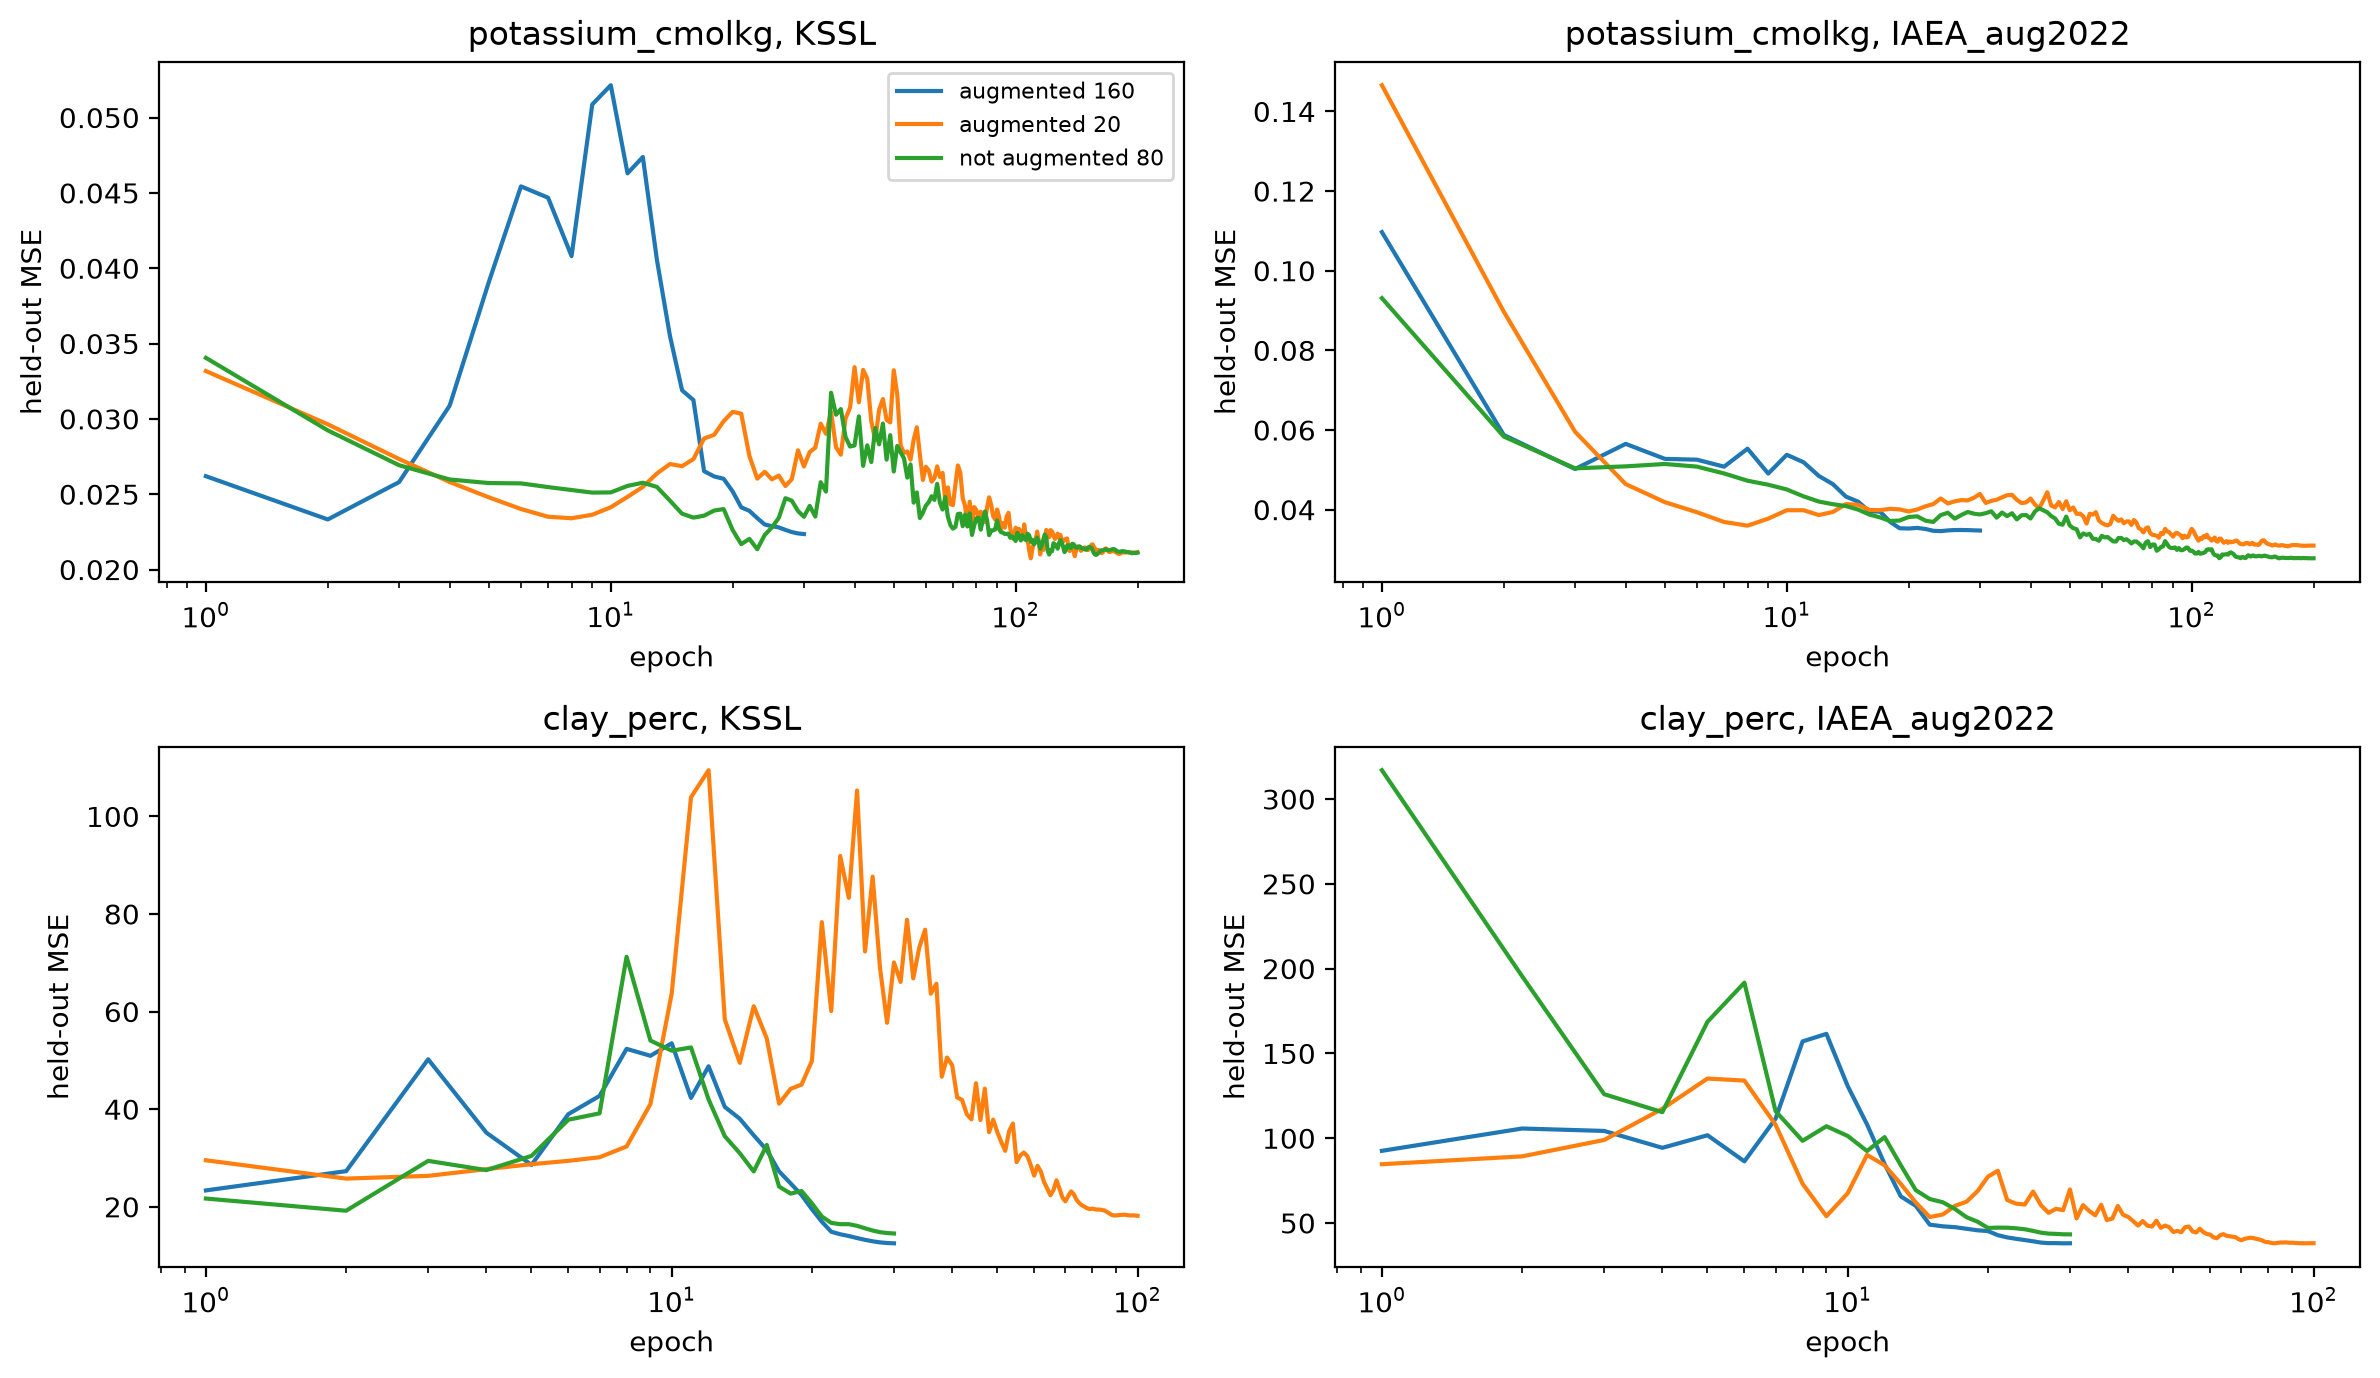

In [ ]:
#| rtdata
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
for (ax, (i, p)) in zip(axs.flat, [(i, p) for p in props for i in insts]):
    for s in starts:
        h = hists[(hists.instrument == i) & (hists.property == p) & (hists.start == s)].groupby('epoch').valid_loss.mean()
        ax.plot(h.index + 1, h.values, label=s)
    ax.set(title=f'{p}, {i}', xlabel='epoch', ylabel='held-out MSE', xscale='log')
axs[0, 0].legend(fontsize=8)
plt.tight_layout();

## Results

**Scores against wet chemistry.** On KSSL, fine-tuning gives the highest R² for both properties and every starting model: 0.87 to 0.91 for clay and 0.60 to 0.63 for K. PLSR trained on the same soils gives 0.81 for clay and 0.15 for K. Zero-shot gives 0.68 to 0.76 for clay and 0.21 to 0.45 for K. For K, ridge regression on block-4 features (0.24 to 0.30) is below zero-shot from the augmented 160 model (0.45). CCC mostly agrees with R². The exception is K on KSSL: zero-shot CCC (0.73 to 0.78) is as high as fine-tuning CCC (0.77), although zero-shot R² is much lower (0.21 to 0.45 against 0.60 to 0.63).

On IAEA, fine-tuning and block-4 ridge give R² 0.60 to 0.73 for clay, against 0.45 for PLSR. For K, all methods except zero-shot give 0.38 to 0.51, and PLSR gives 0.40. Zero-shot on IAEA fails for K with every starting model: R² −2.1 to −3.3, with a bias of +0.66 to +0.87 cmol/kg.

IAEA stays below KSSL with every method, including PLSR trained on the IAEA spectra (clay 0.45 against 0.81). Part of the gap therefore seems to come from the IAEA spectra themselves, not from transfer.

**Paired tests against PLSR.** Fine-tuning and block-4 ridge beat PLSR on most soil groups for K on KSSL (71% to 86% of groups, p ≤ 0.001) and for clay on IAEA (68% to 81%, p ≤ 0.007). For clay on KSSL, fine-tuning lowers the mean squared error of PLSR by a third to a half, but has the smaller error on only 52% to 56% of groups (p = 0.06 to 0.46): the gain comes from a few soils. For K on IAEA, only fine-tuning from the augmented 20 model and block-4 ridge from the augmented 160 model beat PLSR at p < 0.05 (70% of groups, p = 0.02 and 0.03). With about 60 uncorrected tests, a few results at p < 0.05 are expected by chance.

**Starting models.** Augmentation improves zero-shot on IAEA clay: R² changes from −2.73 to 0.27 (augmented 160) and 0.40 (augmented 20), and the augmented models have the smaller error on about 90% of groups (p < 0.001). On KSSL clay, the augmented models are worse zero-shot (p = 0.01 and 0.02). After fine-tuning, the clay difference between starting models is not significant on either instrument (p = 0.20 to 0.64). For K, the augmented 160 model is worse than the unaugmented model after fine-tuning, on KSSL and on IAEA (smaller error on 22% and 29% of groups, p = 0.002 for both). The augmented 20 model is not significantly different (p = 0.19 and 0.68). The cost for K therefore goes with the long augmented pretraining, not with augmentation itself. Each starting model is one pretraining run with seed 42, so these differences include the variation between seeds.

**Distance from the KSSL prediction.** Fine-tuning and block-4 ridge bring the IAEA and KSSL predictions of a soil much closer than zero-shot does: 3.9 to 6.0% clay against 9.9 to 25.7% for zero-shot, and 0.10 to 0.13 against about 0.40 for K on the `log1p` scale. PLSR is further apart than fine-tuning for clay (7.0%) and similar for K (0.12).